<a href="https://colab.research.google.com/github/m4tss0/Calculo-Numerico-2026-2/blob/main/Atividade_Sistemas_Lineares.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Atividade Sistemas Lineares - Cálculo Numérico

**Nome:** Mateus de Lima Alencar Soares  
**RA:** 185301  
**Turma:** Noturno  


## Partes 1, 2 e 4.a) realizadas manualmente na folha:

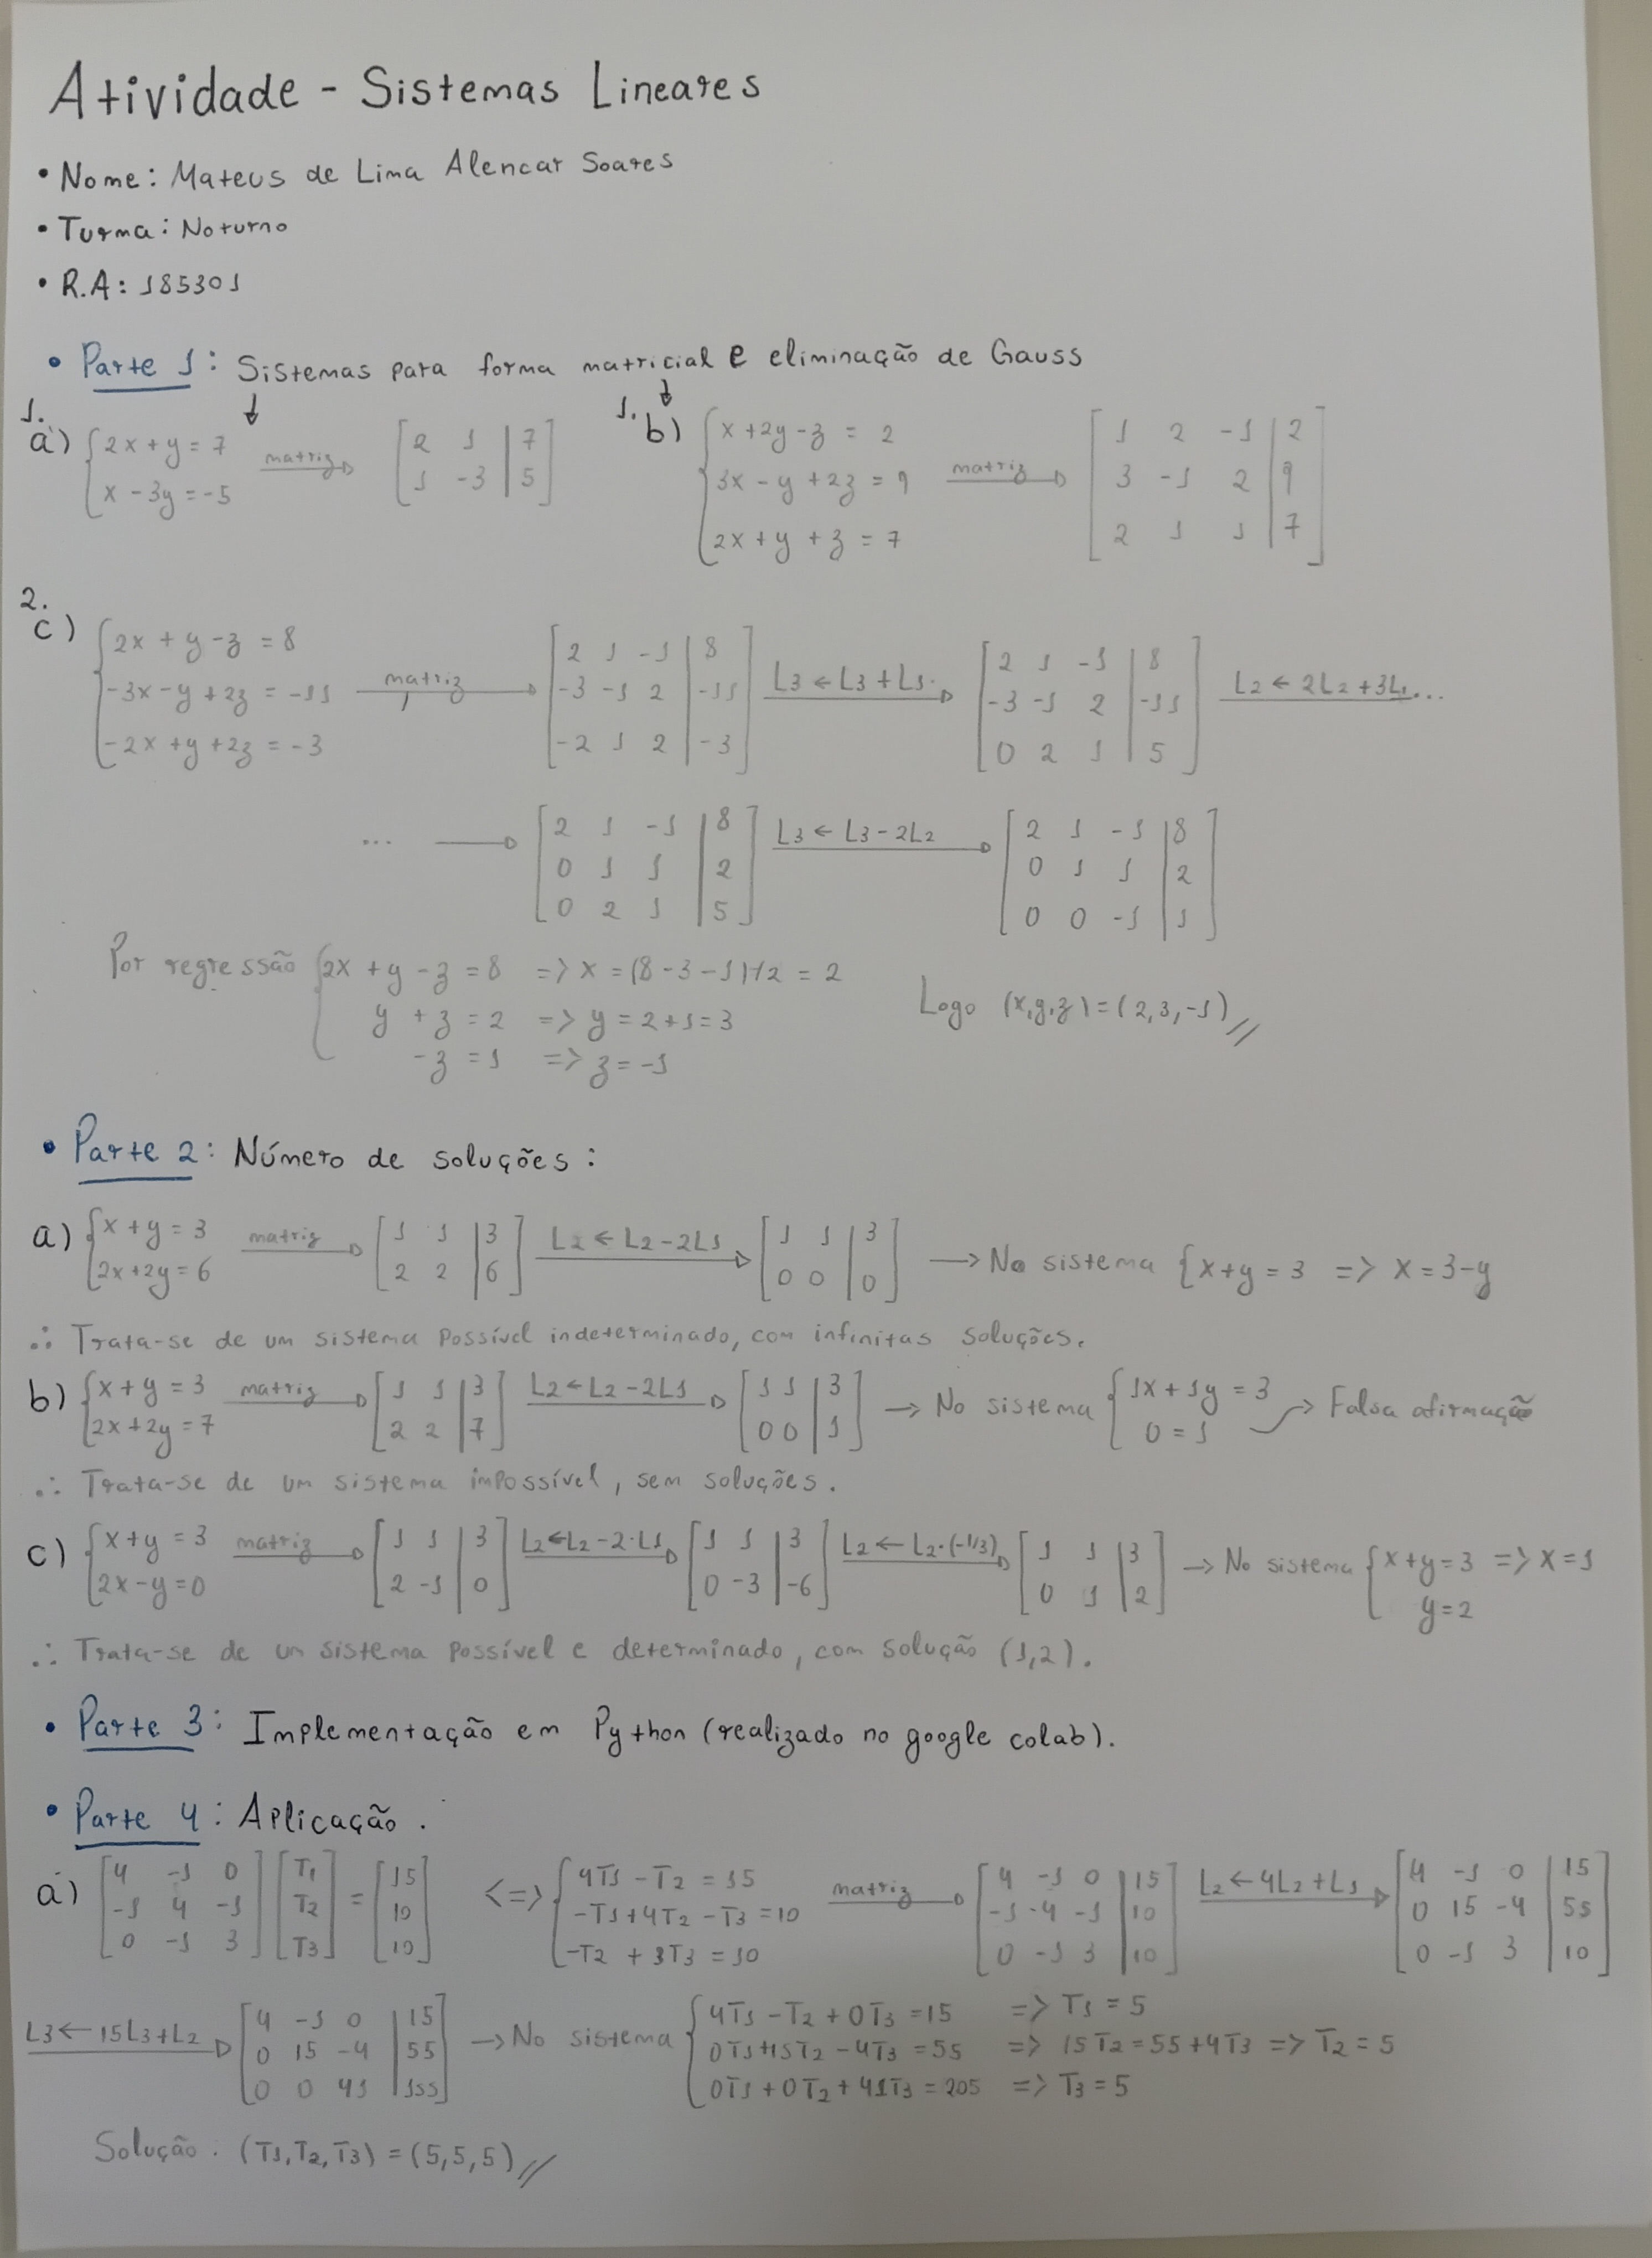

## Parte 3: Implementação Numérica do Método de Gauss em Python

In [ ]:
import numpy as np

def eliminacao_gauss_sem_pivoteamento(A, b):
    """
    Resolve um sistema linear Ax = b utilizando o Método de Eliminação de Gauss
    sem pivoteamento e substituição regressiva.

    Parâmetros:
    -----------
    A : array_like (n x n)
        Matriz de coeficientes do sistema.
    b : array_like (n,)
        Vetor de termos independentes.

    Retorna:
    --------
    x : numpy.ndarray (n,)
        Vetor solução do sistema linear.
    """
    # Converter para arrays de ponto flutuante para evitar divisão inteira
    A = np.array(A, dtype=float)
    b = np.array(b, dtype=float)
    n = len(b)

    # 1. Formar a matriz aumentada [A | b]
    M = np.column_stack([A, b])
    print("Matriz Aumentada Inicial [A | b]:")
    print(M)
    print("-" * 50)

    # 2. Eliminação dos elementos abaixo dos pivôs (Triangularização)
    for k in range(n - 1):
        pivo = M[k, k]

        # Verificação básica de pivô nulo (sem pivoteamento)
        if np.isclose(pivo, 0.0):
            raise ValueError(f"Pivô nulo encontrado na posição M[{k},{k}]. "
                             "O método sem pivoteamento falha nesta matriz.")

        for i in range(k + 1, n):
            # Cálculo do multiplicador m_ik
            m_ik = M[i, k] / pivo

            # Operação elementar de linha: L_i <- L_i - m_ik * L_k
            M[i, k:] -= m_ik * M[k, k:]

    print("Matriz Aumentada Triangular Superior [U | c]:")
    print(M)
    print("-" * 50)

    # 3. Aplicar substituição regressiva
    x = np.zeros(n)
    for i in range(n - 1, -1, -1):
        # Soma dos termos já calculados: sum(U[i, j] * x[j]) para j > i
        soma = np.dot(M[i, i + 1:n], x[i + 1:n])
        # Isolando a incógnita x[i]
        x[i] = (M[i, n] - soma) / M[i, i]

    return x


# ==============================================================================
# TESTE COM O SISTEMA DO EXERCÍCIO 2 E COMPARAÇÃO COM NUMPY
# ==============================================================================

# Sistema do Exercício 2:
# 2x +  y -  z =   8
# -3x -  y + 2z = -11
# -2x +  y + 2z =  -3

A_ex2 = np.array([
    [ 2.,  1., -1.],
    [-3., -1.,  2.],
    [-2.,  1.,  2.]
])

b_ex2 = np.array([8., -11., -3.])

# A) Resolução com a nossa função
x_calculado = eliminacao_gauss_sem_pivoteamento(A_ex2, b_ex2)

# B) Resolução com numpy.linalg.solve
x_numpy = np.linalg.solve(A_ex2, b_ex2)

# C) Exibição dos resultados e comparação
print("\n=== RESULTADOS ===")
print(f"Solução calculada pelo nosso algoritmo: x = {x_calculado}")
print(f"Solução obtida via numpy.linalg.solve: x = {x_numpy}")

# Comparação numérica direta
diferenca_maxima = np.max(np.abs(x_calculado - x_numpy))
print(f"Diferença absoluta máxima entre as soluções: {diferenca_maxima:.2e}")

if np.allclose(x_calculado, x_numpy):
    print("\n✓ O resultado do algoritmo implementado coincide com numpy.linalg.solve!")

Matriz Aumentada Inicial [A | b]:
[[  2.   1.  -1.   8.]
 [ -3.  -1.   2. -11.]
 [ -2.   1.   2.  -3.]]
--------------------------------------------------
Matriz Aumentada Triangular Superior [U | c]:
[[ 2.   1.  -1.   8. ]
 [ 0.   0.5  0.5  1. ]
 [ 0.   0.  -1.   1. ]]
--------------------------------------------------

=== RESULTADOS ===
Solução calculada pelo nosso algoritmo: x = [ 2.  3. -1.]
Solução obtida via numpy.linalg.solve: x = [ 2.  3. -1.]
Diferença absoluta máxima entre as soluções: 5.55e-16

✓ O resultado do algoritmo implementado coincide com numpy.linalg.solve!


## Parte 4.b) Aplicação do Método

In [ ]:
import numpy as np

def resolver_balanco_termico():
    # Definição da matriz A e do vetor b do modelo térmico
    A = np.array([
        [ 4., -1.,  0.],
        [-1.,  4., -1.],
        [ 0., -1.,  3.]
    ])

    b = np.array([15., 10., 10.])

    # 1. Resolução utilizando Eliminação de Gauss sem pivoteamento
    n = len(b)
    M = np.column_stack([A.copy(), b.copy()])

    # Triangularização
    for k in range(n - 1):
        for i in range(k + 1, n):
            m_ik = M[i, k] / M[k, k]
            M[i, k:] -= m_ik * M[k, k:]

    # Substituição Regressiva
    T = np.zeros(n)
    for i in range(n - 1, -1, -1):
        soma = np.dot(M[i, i + 1:n], T[i + 1:n])
        T[i] = (M[i, n] - soma) / M[i, i]

    # 2. Validação com numpy.linalg.solve
    T_numpy = np.linalg.solve(A, b)

    print("=== RESULTADOS DO MODELO DE BALANÇO TÉRMICO ===")
    print(f"Temperatura T1: {T[0]:.2f}")
    print(f"Temperatura T2: {T[1]:.2f}")
    print(f"Temperatura T3: {T[2]:.2f}")
    print("-" * 45)
    print(f"Vetor Solução T (Algoritmo): {T}")
    print(f"Vetor Solução T (NumPy):     {T_numpy}")

# Execução do programa
resolver_balanco_termico()

=== RESULTADOS DO MODELO DE BALANÇO TÉRMICO ===
Temperatura T1: 5.00
Temperatura T2: 5.00
Temperatura T3: 5.00
---------------------------------------------
Vetor Solução T (Algoritmo): [5. 5. 5.]
Vetor Solução T (NumPy):     [5. 5. 5.]
